## Load  packages

In [1]:
import pandas as pd
import numpy as np
import io
import itertools
import yaml
import math
import matplotlib.pyplot as plt
plt.style.use('style_sr15.mplstyle')
%matplotlib inline
import pyam
from utils import boxplot_by_cat

<IPython.core.display.Javascript object>

## Read the AR6 dataframe for the world 

In [ ]:
df = pyam.IamDataFrame(data='AR6_Scenarios_Database_World_v1.0.csv')

# 1. Final Energy Space Heating

### Indentifying scenarios with Final Energy Demand on Space Heating

In [3]:
required_variable = 'Final Energy|Residential and Commercial|Commercial|Heating|Space'

The cell below provides all scenraios that have the required valrables available

In [4]:
df.filter(variable=required_variable).model

['GCAM 5.3', 'IEA Energy Technology Perspectives Model 2020', 'IMAGE 3.2']

Based on the tables above and further evaluation of the data, GCAM 5.3 was identified as the model for the evaluation of the final energy space heating demand.

Since the dataset on the required variable was only available for the NGFS (Network Greening for financial system) scenarios upto 2100, these scenrios were further analyzed.

In [5]:
scenario_list_GCAM = [scenario for scenario in df.filter(model='GCAM 5.3').scenario if scenario.startswith('NGFS2')]

In [6]:
scenario_list_GCAM

['NGFS2_Below 2°C',
 'NGFS2_Current Policies',
 'NGFS2_Delayed Transition',
 'NGFS2_Divergent Net Zero Policies',
 'NGFS2_Nationally Determined Contributions (NDCs)',
 'NGFS2_Net-Zero 2050']

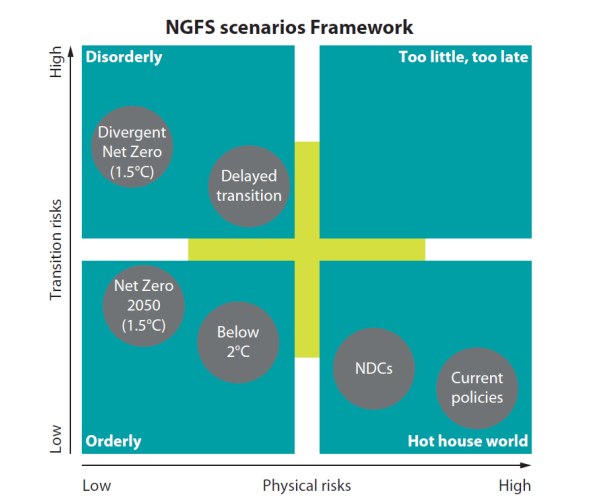

(Source: Bertram et al., 2021)

Source: https://data.ene.iiasa.ac.at/ngfs/#/workspaces/82

In [7]:
scenario_list_GCAM_orderly = ['NGFS2_Below 2°C','NGFS2_Net-Zero 2050']

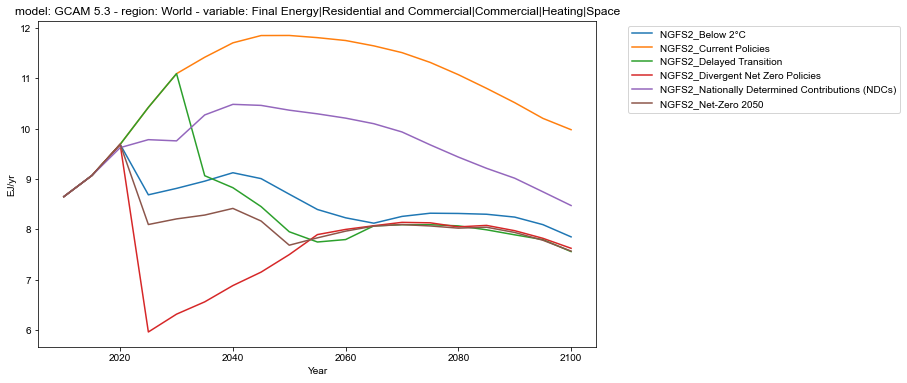

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
df.filter(variable='Final Energy|Residential and Commercial|Commercial|Heating|Space',scenario = scenario_list_GCAM).plot(ax=ax,legend=True)
ax.legend(loc='upper center', bbox_to_anchor=(1.3, 1))
plt.show() 

For all the observed scenarios a decreasing trend in the final energy demand is observed post 2030 which are most likely due to the anticipated improvement in building rennovation measures. The trend could also be associated to increasing global temperatures resulting in lower heating demands.

In [ ]:
df_regional = pyam.IamDataFrame(data='AR6_Scenarios_Database_R5_regions_v1.0.csv')

### Regional NGFS oderly scenarios

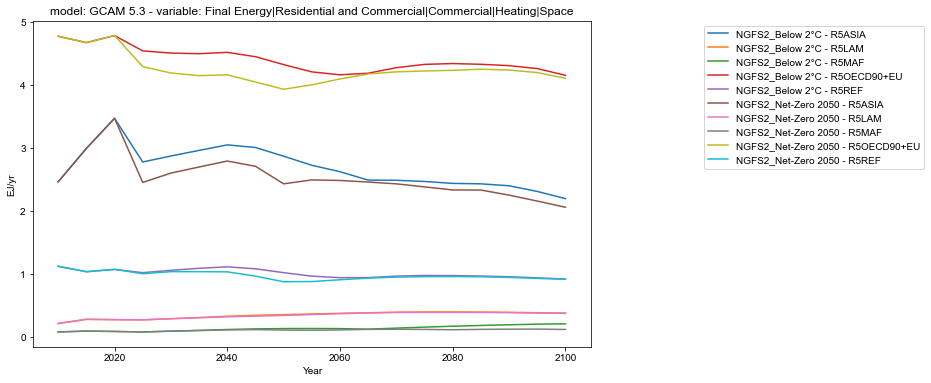

In [12]:
fig, ax = plt.subplots(figsize=(10,6))
df_regional.filter(variable='Final Energy|Residential and Commercial|Commercial|Heating|Space',scenario = scenario_list_GCAM_orderly).plot(ax=ax,legend=True)
ax.legend(loc='upper center', bbox_to_anchor=(1.4, 1))
plt.show() 

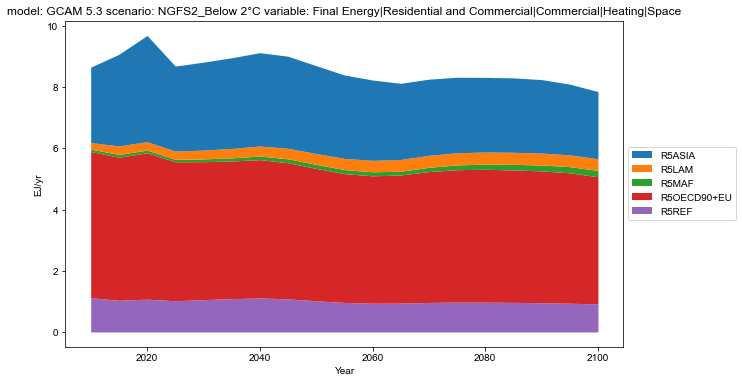

In [13]:
#NGFS below 2°C
data = df_regional.filter(variable='Final Energy|Residential and Commercial|Commercial|Heating|Space').filter(model='GCAM 5.3').filter(scenario= scenario_list_GCAM[0])
fig, ax = plt.subplots(figsize=(10,6))
data.plot(ax=ax, kind ='stack', stack = 'region')
plt.show()

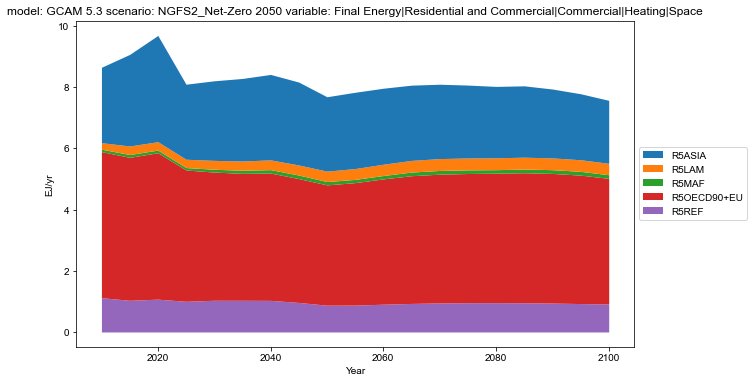

In [14]:
#NGFS Net zero 2050
data = df_regional.filter(variable='Final Energy|Residential and Commercial|Commercial|Heating|Space').filter(model='GCAM 5.3').filter(scenario= scenario_list_GCAM[5])
fig, ax = plt.subplots(figsize=(10,6))
data.plot(ax=ax, kind ='stack', stack = 'region')
plt.show()

# 2. Emissions

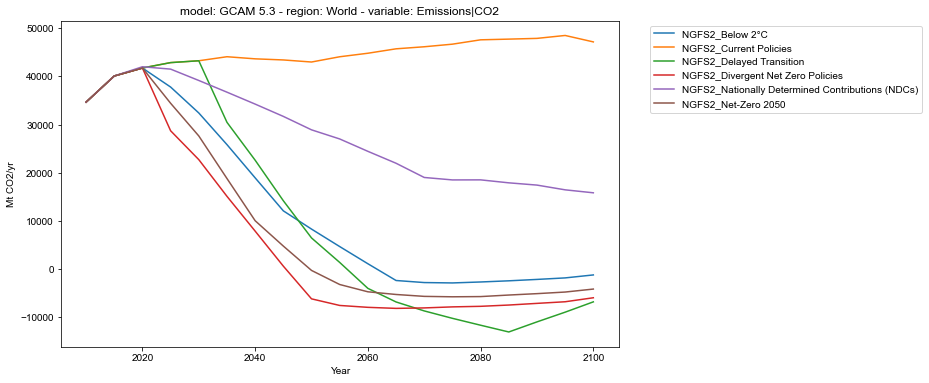

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
df.filter(model = 'GCAM 5.3',variable='Emissions|CO2',scenario = scenario_list_GCAM).plot(ax=ax,legend=True)
ax.legend(loc='upper center', bbox_to_anchor=(1.3, 1))
plt.show() 

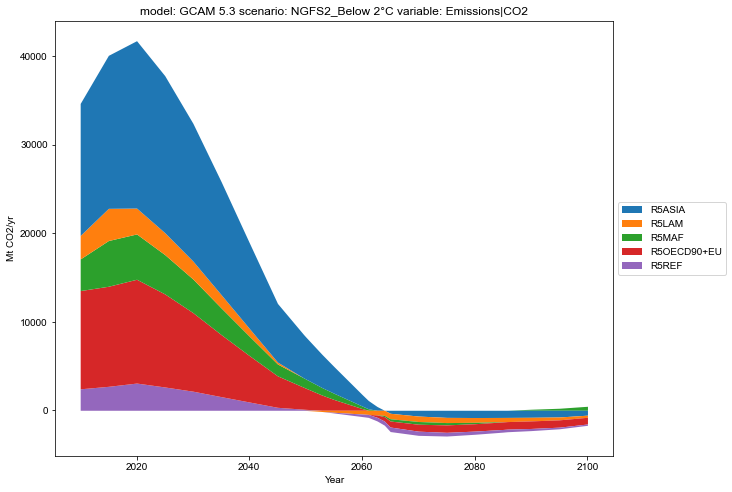

In [16]:
#NGFS below 2°C
data = df_regional.filter(variable='Emissions|CO2').filter(model='GCAM 5.3').filter(scenario= scenario_list_GCAM[0])
fig, ax = plt.subplots(figsize=(10, 8))
data.plot(ax=ax, kind ='stack', stack = 'region')
plt.show()

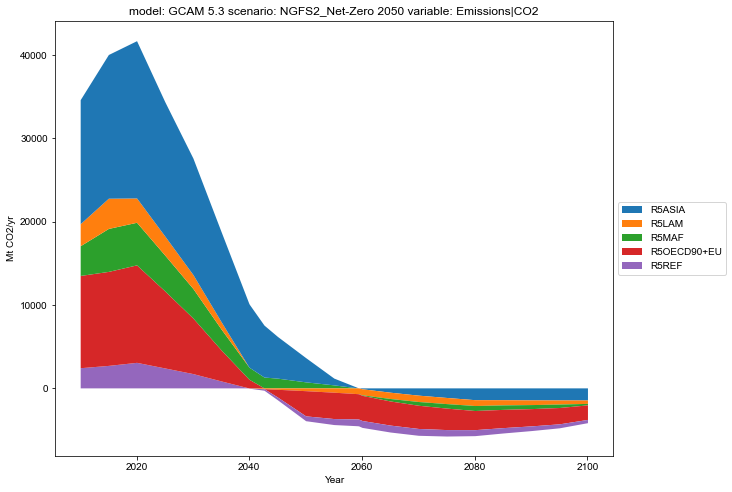

In [17]:
#NGFS Net zero 2050
data = df_regional.filter(variable='Emissions|CO2').filter(model='GCAM 5.3').filter(scenario= scenario_list_GCAM[5])
fig, ax = plt.subplots(figsize=(10, 8))
data.plot(ax=ax, kind ='stack', stack = 'region')
plt.show()

# Conclusion

The anticipated reduction in the space heating demand in all scenarios, emphasis on building rennovation and energy efficiency is important. Also would be necessary to look into the increasing temperatres and their realtionship with the reducing demand. 

## License

   [<img style="float: right;" src="https://img.shields.io/badge/License-Apache%202.0-blue.svg">](https://opensource.org/licenses/Apache-2.0)
   
   Copyright 2022 Aadit Malla

   Licensed under the Apache License, Version 2.0 (the "License");
   you may not use this file except in compliance with the License.
   You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

   Unless required by applicable law or agreed to in writing, software
   distributed under the License is distributed on an "AS IS" BASIS,
   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
   See the License for the specific language governing permissions and
   limitations under the License.

## References
[1] . Christoph Bertram, Jérôme Hilaire, ElmarKriegler, ThessaBeck, DavidN.Bresch,Leon Clarke,Ryna Cui,Jae Edmonds,Molly Charles, Alicia Zhao, Chahan Kropf,Inga Sauer, Quentin Lejeune, Peter Pfleiderer,Jihoon Min, Franziska Piontek, Joeri Rogelj, Carl-Friedrich Schleussner, Fabio Sferra, Bas van Ruijven, ShaYu, Dawn Holland, Iana Liadze, and Ian Hurst.
NGFS Climate Scenario Database, Technical Document V2.2, Hune 2021
https://www.ngfs.net/sites/default/files/ngfs_climate_scenarios_technical_documentation__phase2_june2021.pdf

[2] IIASA release 2.2.
NHFS Scenario Explorer<br>
https://data.ene.iiasa.ac.at/ngfs/#/workspaces/82

[3]  Daniel Huppmann, Matthew Gidden, Zebedee Nicholls, Jonas Hörsch, Robin Lamboll, Paul Natsuo Kishimoto, Thorsten Burandt, Oliver Fricko, Edward Byers, Jarmo Kikstra, Maarten Brinkerink, Maik Budzinski, Florian Maczek, Sebastian Zwickl-Bernhard, Lara Welder, Erik Francisco Álvarez Quispe, and Christopher J. Smith.
pyam: Analysis and visualisation of integrated assessment and macro-energy scenarios.
Open Research Europe, 2021. 

doi: https://doi.org/10.12688/openreseurope.13633.2 

